In [109]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [110]:
def show(*images, titles=None, size=3, cols=4):
    cols = min(cols, len(images))
    rows = -(-len(images) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.flat[len(images):]:
        ax.axis('off')
    for i, (ax, im) in enumerate(zip(axes.flat, images)):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(im)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color('blue')
            spine.set_linewidth(1.5)
        if titles:
            ax.set_title(titles[i])
    plt.tight_layout()
    plt.show()

def norm(img):
    return cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def inv(img):
    return 255 - norm(img)

In [111]:
DATA_DIR = Path().resolve().parent / 'data'
BBDD_DIR = DATA_DIR / 'BBDD'
QSD2 = DATA_DIR / 'qsd2_w2'

IMG_ID = '00029'
img = cv2.cvtColor(cv2.imread(QSD2 / (IMG_ID + '.jpg')), cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
h, w = gray.shape

In [112]:
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.int16)
H, S, V = cv2.split(img_hsv)

In [113]:
v = 15
border = np.zeros(gray.shape, bool)
border[:v, :] = border[-v:, :] = border[:, :v] = border[:, -v:] = True

wall_pixels = img_hsv[border]
wall_mean = np.mean(wall_pixels, axis=0)
wall_mean

array([102.34005764,  34.55529939, 159.87592059])

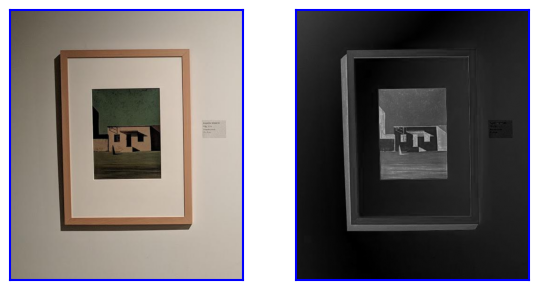

In [114]:
weights = np.array([0, 0.226156, 0.648148])

delta = img_hsv - wall_mean
distance = np.sqrt(np.sum(weights * delta**2, axis=2))

show(img, distance)

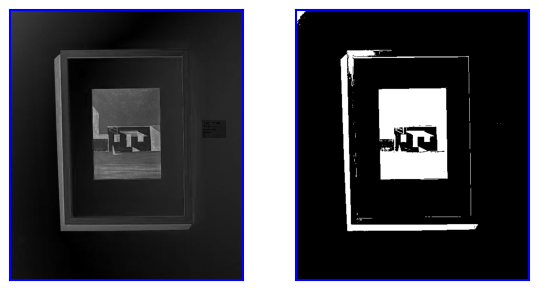

In [115]:
t, thr = cv2.threshold(distance.astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show(distance, thr)

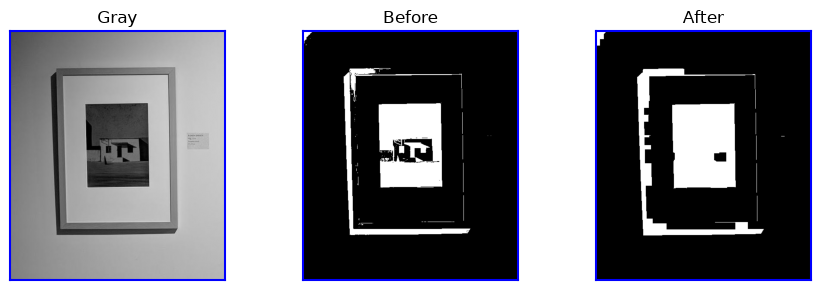

In [116]:
n = int(min(h,w)*0.034171)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (n,n))

mask = cv2.morphologyEx(thr, cv2.MORPH_CLOSE, kernel)

show(gray, thr, mask, titles=['Gray', 'Before', 'After'])

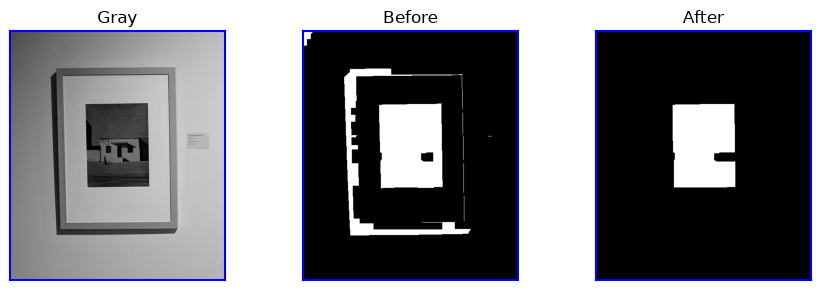

In [117]:
n = int(min(h,w)*0.1)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (n,n))

last = mask.copy()
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

show(gray, last, mask, titles=['Gray', 'Before', 'After'])

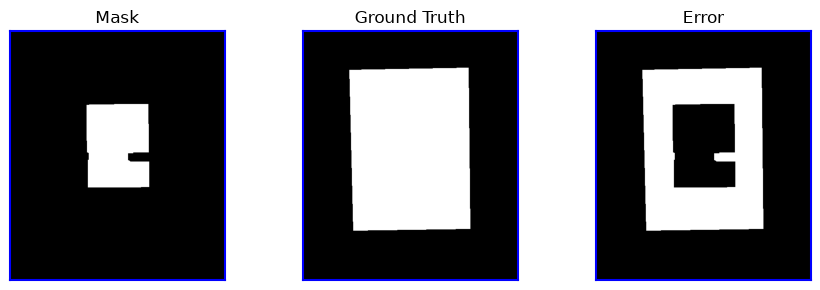

In [118]:
gt = cv2.imread(QSD2 / (IMG_ID+'.png'), cv2.IMREAD_GRAYSCALE)

err = cv2.absdiff(mask, gt)

show(mask, gt, err, titles=['Mask', 'Ground Truth', 'Error'])